In [6]:
!rm -rf clone && git clone https://github.com/pui-sum-rv/lab3 clone && cp -a clone/. .

Cloning into 'clone'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (53/53), done.
remote: Compressing objects: 100% (47/47), done.
remote: Total 53 (delta 11), reused 38 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (53/53), 5.00 MiB | 22.46 MiB/s, done.
Resolving deltas: 100% (11/11), done.


In [7]:
import os

for root, dirs, files in os.walk("."):
    for file in files:
        print(os.path.join(root, file))

./README.md
./lab3.ipynb
./example.ipynb
./.config/config_sentinel
./.config/active_config
./.config/.last_update_check.json
./.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
./.config/.last_opt_in_prompt.yaml
./.config/gce
./.config/.last_survey_prompt.yaml
./.config/default_configs.db
./.config/logs/2026.09.16/13.26.04.283691.log
./.config/logs/2026.09.16/13.26.29.139725.log
./.config/logs/2026.09.16/13.26.15.129583.log
./.config/logs/2026.09.16/13.26.30.459687.log
./.config/logs/2026.09.16/13.26.17.091876.log
./.config/logs/2026.09.16/13.25.37.877256.log
./.config/configurations/config_default
./.git/index
./.git/packed-refs
./.git/description
./.git/HEAD
./.git/config
./.git/logs/HEAD
./.git/logs/refs/heads/main
./.git/logs/refs/remotes/origin/HEAD
./.git/info/exclude
./.git/objects/pack/pack-72d9d704f16af42d6cc1ba1c522ec0ec3c5c5c8d.idx
./.git/objects/pack/pack-72d9d704f16af42d6cc1ba1c522ec0ec3c5c5c8d.rev
./.git/objects/pack/pack-72d9d704f16af42d6cc1ba1c522ec

In [11]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

image = cv.imread('./images/pepper.bmp', cv.IMREAD_GRAYSCALE)

print(image.shape)

(512, 512)


In [12]:
def gaussian_noise(img, mu, sigma):
    noise = np.random.normal(mu, sigma, img.shape)
    return noise.astype(np.uint8)

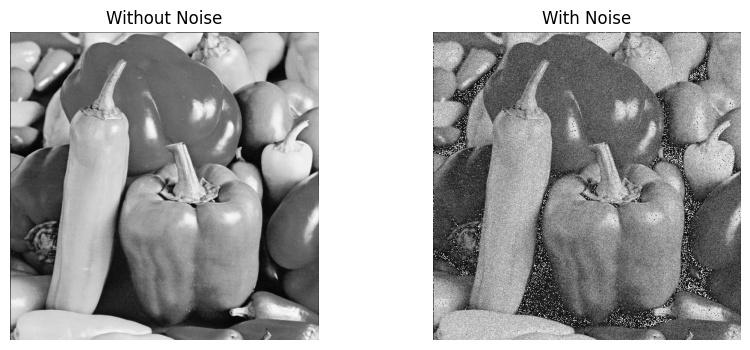

In [13]:
noise = gaussian_noise(image, 0, 20)

image_with_noise = image + noise

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Without Noise')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(image_with_noise, cmap='gray')
plt.title('With Noise')
plt.axis('off')

plt.show()

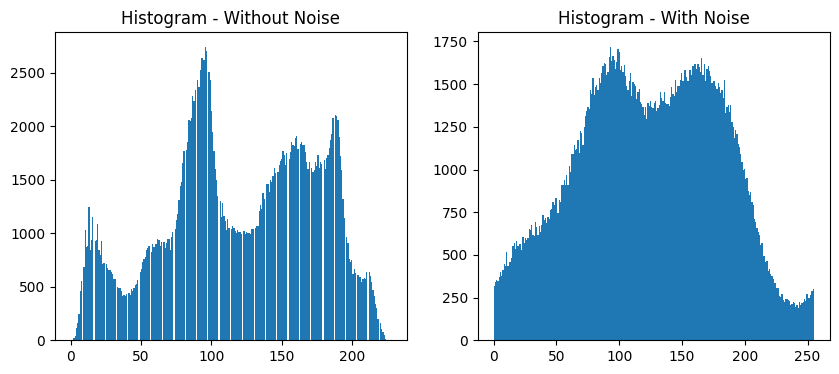

In [14]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(image.flatten(), bins=256)
plt.title('Histogram - Without Noise')

plt.subplot(1, 2, 2)
plt.hist(image_with_noise.flatten(), bins=256)
plt.title('Histogram - With Noise')

plt.show()

In [15]:
def uniform_noise(img, a, b):
    noise = np.random.uniform(a, b, img.shape)
    return noise.astype(np.uint8)

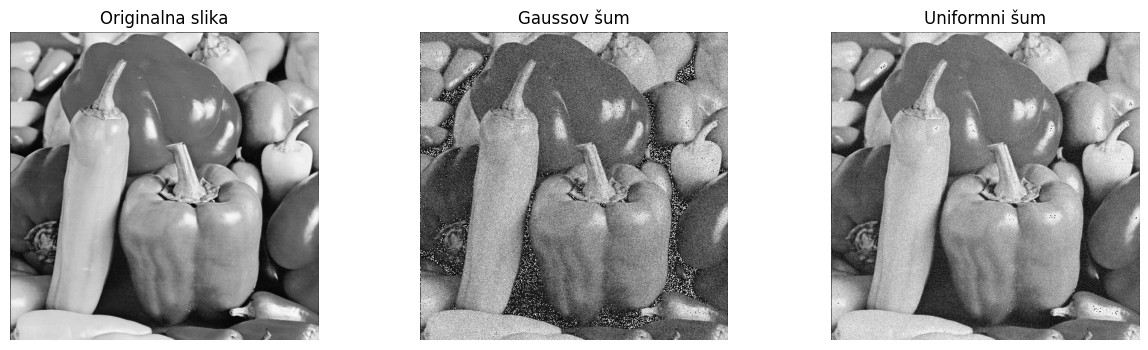

In [16]:
gaussian = gaussian_noise(image, 0, 20)
uniform = uniform_noise(image, 0, 40)

image_gaussian = image + gaussian
image_uniform = image + uniform

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Originalna slika')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(image_gaussian, cmap='gray')
plt.title('Gaussov šum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(image_uniform, cmap='gray')
plt.title('Uniformni šum')
plt.axis('off')

plt.show()

In [17]:
def salt_n_pepper_noise(img, percent=10):
    limit = ((float(percent)/2.0)/100.0) * 255.0
    noise = np.random.uniform(0,255, img.shape)
    return noise.astype(np.uint8)

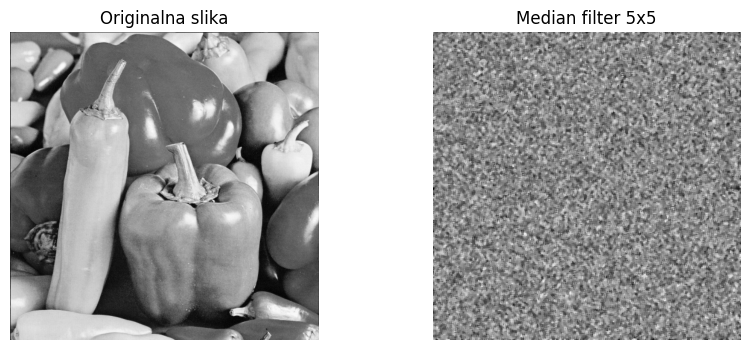

In [18]:
# Salt and pepper šum 10%
noise_sp = salt_n_pepper_noise(image, 10)
image_sp = image + noise_sp

# Median filter
median = cv.medianBlur(image_sp, 5)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Originalna slika')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(median, cmap='gray')
plt.title('Median filter 5x5')
plt.axis('off')

plt.show()

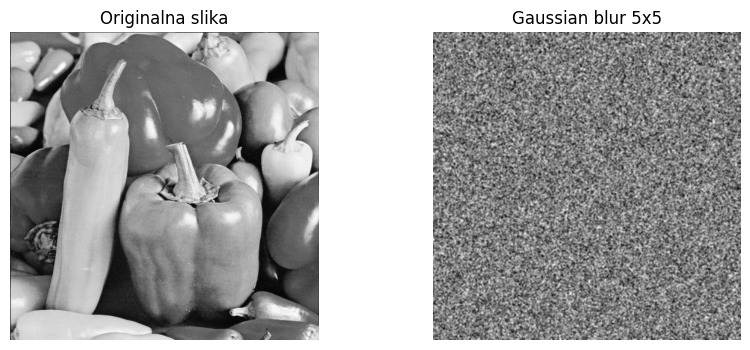

In [19]:
# Gaussian blur
blur = cv.GaussianBlur(image_sp, (5, 5), 0)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Originalna slika')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(blur, cmap='gray')
plt.title('Gaussian blur 5x5')
plt.axis('off')

plt.show()

In [20]:
# Gaussov šum sa sigma = 15
gaussian = gaussian_noise(image, 0, 15)

image_gaussian = image + gaussian

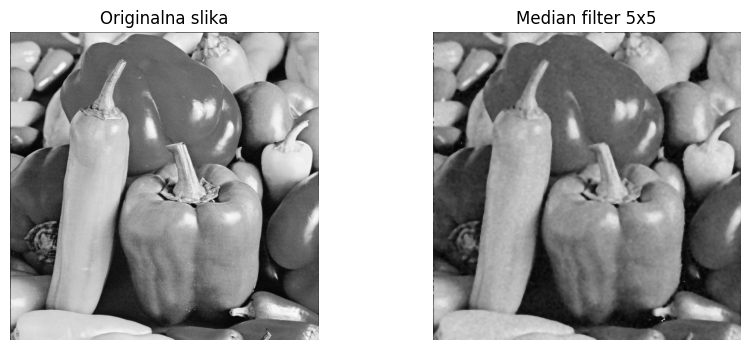

In [21]:
median_gaussian = cv.medianBlur(image_gaussian, 5)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Originalna slika')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(median_gaussian, cmap='gray')
plt.title('Median filter 5x5')
plt.axis('off')

plt.show()

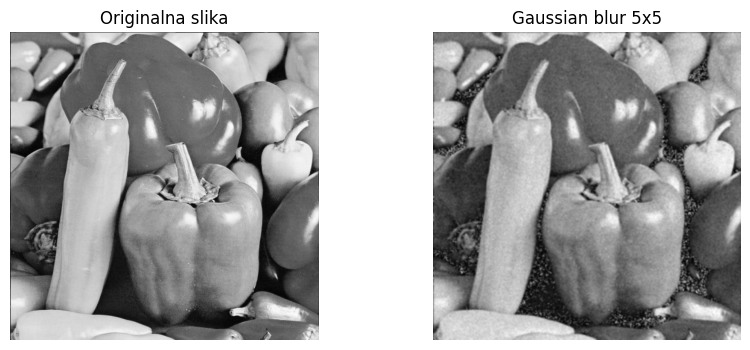

In [22]:
blur_gaussian = cv.GaussianBlur(image_gaussian, (5, 5), 0)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Originalna slika')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(blur_gaussian, cmap='gray')
plt.title('Gaussian blur 5x5')
plt.axis('off')

plt.show()